# Eksperimen Pribadi — Tugas 3 Bagian B.ii: Topic Modeling (LDA & BERTopic)

> "Pemodelan topik (LDA, BERTopic) untuk mengategorikan tema-tema geopolitik sebelum ekstraksi fitur."

**Motivasi:** berita sehari bercampur tema (perang, sanksi, energi, bank sentral, ...). Merata-rata semuanya jadi satu skor/vektor bisa menghapus efek tema yang arahnya berlawanan. Di sini berita dikategorikan ke tema dulu, baru fitur diambil per tema.

**Tiga hipotesis:**
1. **H1 — komposisi tema:** porsi berita tiap tema per hari memberi informasi di luar fitur kurs.
2. **H2 — sentimen per tema:** sentimen FinBERT khusus tema (mis. energi) lebih berhubungan dengan return besok daripada sentimen global.
3. **H3 — tema bermakna & stabil:** tema bisa dinamai dan prevalensinya masuk akal dari waktu ke waktu (nilai deskriptif untuk laporan).

| Set | Fitur |
|---|---|
| **A** | 7 fitur kurs |
| **B** | A + 16 lexicon |
| **G** | A + 1 sentimen FinBERT global (pembanding H2) |
| **T-LDA / T-BERTopic (porsi)** | A + porsi tema harian |
| **T-... (sentimen per tema)** | A + sentimen FinBERT harian per tema utama |

**Aturan:** model topik di-fit **hanya pada artikel train**; jumlah topik K dipilih dari koherensi di train (bukan dari RMSE val); val/test hanya di-transform. Pembanding utama tetap baris Konstan.

**Prasyarat:** `pip install gensim bertopic` (membawa `umap-learn`, `hdbscan`). Cache `MiniLM_cw160_mc5_ml256.npz` (untuk BERTopic) dan `FinBERT_cw300_mc2_ml512.npz` (untuk sentimen per tema) ada di `cache_embeddings/`. Bagian yang cache-nya tidak ada akan dilewati.

## 0. Setup

In [5]:
%pip install gensim bertopic

Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 9.9 MB/s  0:00:00 eta 0:00:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.4/24.4 MB 14.4 MB/s  0:00:01m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.8/28.8 MB 23.3 MB/s  0:00:01m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 26.3 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 21.0 MB/s  0:00:00
  Created wheel for hdbscan: filename=hdbscan-0.8.42-cp39-cp39-macosx_10_9_universal2.whl size=1522647 sha256=725eca0e73059a4465a2f9eadbcc9dfd5e6f7789f87bbbd21f00dd34319b2988
  Stored in directory: /Users/farsyaant/Library/Caches/pip/wheels/ed/0d/10/77e52180d41859778f847c91db4c9d7c19af9d3b9975268d1c
Successfully built hdbscan
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [1]:
import sys, re, json, time, warnings
sys.dont_write_bytecode = True
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import balanced_accuracy_score, matthews_corrcoef
warnings.filterwarnings("ignore")

def find_root():
    """Cari root repo dari folder notebook (jalan dari notebook/ maupun src/notebook/)."""
    here = Path.cwd().resolve()
    for q in (here, *here.parents):
        if (q / "data" / "export" / "articles.parquet").exists() and (q / "src" / "eval_utils.py").exists():
            return q
    raise FileNotFoundError("root repo (data/export + src/eval_utils.py) tidak ditemukan dari " + str(here))

ROOT = find_root()
sys.path.append(str(ROOT / "src"))
from eval_utils import evaluate, naive_baselines

EXPORT_DIR = ROOT / "data" / "export"
CACHE_DIR = Path("cache_embeddings"); CACHE_DIR.mkdir(exist_ok=True)
SEED = 42
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)
print("root repo:", ROOT)

root repo: /Users/farsyaant/nlpproject-baru


## 1. Muat data dan split (sama seperti notebook sebelumnya)

In [6]:
articles = pd.read_parquet(EXPORT_DIR / "articles.parquet").sort_values("article_id").reset_index(drop=True)
prices   = pd.read_parquet(EXPORT_DIR / "prices_daily.parquet")
sent     = pd.read_parquet(EXPORT_DIR / "sentiment_daily.parquet")
splits   = json.loads((EXPORT_DIR / "splits.json").read_text())

KURS_COLS = ["kurs_lag1", "kurs_lag2", "kurs_lag3", "kurs_lag4", "kurs_lag5", "kurs_roll_mean5", "kurs_roll_std5"]
LEX_COLS = [c for c in sent.columns if c not in ("date", "news_count")]
assert len(KURS_COLS) == 7 and len(LEX_COLS) == 16

daily = (prices.merge(sent[["date", "news_count"] + LEX_COLS], on="date", how="left")
               .sort_values("date").reset_index(drop=True))
assert daily[LEX_COLS].notna().all().all()
for s in ("train", "val", "test"):
    assert (daily["split"] == s).sum() == splits[s]["n"]
tr = (daily["split"] == "train").to_numpy(); va = (daily["split"] == "val").to_numpy(); te = (daily["split"] == "test").to_numpy()
y = daily["target"].to_numpy()

articles["split"] = articles["aligned_trading_date"].map(dict(zip(daily["date"], daily["split"])))
articles["text_raw"] = articles["title"].fillna("").str.strip() + ". " + articles["full_text"].fillna("").str.strip()
print("baris per split:", tr.sum(), va.sum(), te.sum())
print(articles["split"].value_counts(dropna=False).to_string())

baris per split: 836 178 180
split
train    2489
test     1220
val       619
NaN         4


## 2. Pra-pemrosesan untuk topic modeling

Teks = `title. full_text` (asli), huruf kecil, token alfabet ≥ 3 huruf, **stopword dibuang** (stopword umum + kata berita generik seperti "said", "year"). Tanpa lemmatisasi. Topic modeling berbasis kata sangat sensitif pada kata umum, jadi langkah ini penting.

Kamus dan filter frekuensi dibangun **dari artikel train saja**.

In [7]:
DOMAIN_STOP = {"said", "say", "says", "year", "years", "new", "also", "would", "could", "one", "two", "like",
               "just", "percent", "according", "told", "may", "last", "first", "still", "even", "much", "many",
               "since", "week", "month", "time", "company", "companies", "cnbc", "reuters", "getty", "images",
               "video", "watch", "https", "com", "inc", "corp"}
STOP = set(ENGLISH_STOP_WORDS) | DOMAIN_STOP
TOKEN_RE = re.compile(r"[a-z]{3,}")
def tok(text): return [w for w in TOKEN_RE.findall(text.lower()) if w not in STOP]

articles["toks"] = articles["text_raw"].map(tok)
is_tr = (articles["split"] == "train").to_numpy()
has_split = articles["split"].notna().to_numpy()
print(f"artikel train: {is_tr.sum()} | rata-rata token setelah stopword: {articles['toks'].map(len).mean():.0f}")

artikel train: 2489 | rata-rata token setelah stopword: 412


## 3. LDA (gensim)

Jumlah topik K dipilih dari **koherensi c_v pada data train** (lebih tinggi = tema lebih mudah ditafsirkan manusia). Untuk kecepatan, koherensi dihitung pada 200 token pertama tiap artikel. Val/test hanya di-*transform* dengan model yang sudah dilatih.

In [8]:
from gensim.corpora import Dictionary
from gensim.models import LdaModel, CoherenceModel

train_toks = articles.loc[is_tr, "toks"].tolist()
dct = Dictionary(train_toks); dct.filter_extremes(no_below=10, no_above=0.4, keep_n=5000)   # dari TRAIN
bow_all = [dct.doc2bow(t) for t in articles["toks"]]
bow_tr = [b for b, m in zip(bow_all, is_tr) if m]
print("kosakata LDA:", len(dct))

KS_LDA = (5, 8, 12, 16)
coh_texts = [t[:200] for t in train_toks]
LDAS, coh_rows = {}, []
for K in KS_LDA:
    t0 = time.time()
    m = LdaModel(bow_tr, id2word=dct, num_topics=K, passes=8, iterations=100,
                 random_state=SEED, alpha="auto", eta="auto")
    c = CoherenceModel(model=m, texts=coh_texts, dictionary=dct, coherence="c_v", processes=1).get_coherence()
    LDAS[K] = m; coh_rows.append({"K": K, "koherensi_c_v": round(c, 4), "detik": round(time.time() - t0)})
coh = pd.DataFrame(coh_rows); print(coh.to_string(index=False))
K_LDA = int(coh.loc[coh["koherensi_c_v"].idxmax(), "K"]); lda = LDAS[K_LDA]
print("K terpilih (koherensi tertinggi di train):", K_LDA)

kosakata LDA: 5000
 K  koherensi_c_v  detik
 5         0.5737     11
 8         0.5260     12
12         0.5317     13
16         0.5356     17
K terpilih (koherensi tertinggi di train): 5


In [9]:
def doc_topics(model, bows, K):
    out = np.zeros((len(bows), K))
    for i, b in enumerate(bows):
        for k, p in model.get_document_topics(b, minimum_probability=0.0):
            out[i, k] = p
    return out

THETA = doc_topics(lda, bow_all, K_LDA)           # porsi tema tiap artikel (semua split, model dari train)
LDA_HARD = THETA.argmax(1)                         # tema dominan tiap artikel
titles = articles["title"].fillna("").to_numpy()
for k in range(K_LDA):
    words = ", ".join(w for w, _ in lda.show_topic(k, topn=8))
    idx = np.where(is_tr)[0][np.argsort(-THETA[is_tr, k])[:2]]
    print(f"T{k:02d} [{THETA[is_tr, k].mean():5.1%} dari train] {words}")
    for i in idx: print("      -", titles[i][:100])

T00 [21.4% dari train] trump, biden, chinese, beijing, minister, security, european, foreign
      - RFK Jr. endorses Trump after weeks of back-channel courtship
      - Election win for Russia-friendly party in Georgia sets the stage for protests and possible violence
T01 [32.8% dari train] oil, prices, inflation, growth, markets, bank, rate, demand
      - Stocks could take their cue from oil, inflation and interest rates in the week ahead
      - Economists see UK cutting interest rates more substantially as inflation pressures ease
T02 [12.4% dari train] russian, military, putin, nuclear, north, korea, nato, ukrainian
      - Ukraine must decide how its Russian incursion ends — advance further or retreat before it’s ...
      - Russia signals its official stance on using nuclear weapons is about to change, accusing the ...
T03 [22.6% dari train] billion, chinese, government, business, tech, think, industry, technology
      - Inside Europe’s tech hubs: France’s AI push puts it on t

## 4. BERTopic (memakai embedding MiniLM dari cache)

BERTopic = embedding kalimat → UMAP → HDBSCAN → kata kunci c-TF-IDF. Embedding tidak dihitung ulang: memakai cache MiniLM artikel dari Bagian B. Model di-fit pada artikel **train**, lalu val/test lewat `transform`. HDBSCAN membiarkan sebagian artikel **tanpa topik** (outlier, id −1); porsinya dilaporkan.

In [10]:
BT_OK = False
try:
    from bertopic import BERTopic
    from umap import UMAP
    from hdbscan import HDBSCAN
    mini_f = CACHE_DIR / "MiniLM_cw160_mc5_ml256.npz"
    if not mini_f.exists():
        print("cache MiniLM belum ada -> BERTopic dilewati")
    else:
        E = np.load(mini_f, allow_pickle=True)["A"]
        docs = articles["text_raw"].tolist()
        MIN_CLUSTER = 40          # ukuran klaster minimum; kecilkan untuk tema lebih banyak
        bt = BERTopic(
            embedding_model=None,
            umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=SEED),
            hdbscan_model=HDBSCAN(min_cluster_size=MIN_CLUSTER, metric="euclidean",
                                  cluster_selection_method="eom", prediction_data=True),
            vectorizer_model=CountVectorizer(stop_words=list(STOP), min_df=5, ngram_range=(1, 2)),
            calculate_probabilities=False, verbose=False)
        tr_idx = np.where(is_tr)[0]
        bt.fit([docs[i] for i in tr_idx], embeddings=E[tr_idx])                    # FIT hanya train
        all_topics, _ = bt.transform(docs, embeddings=E)                           # val/test: transform saja
        BT = np.array(all_topics)
        T_IDS = sorted(set(BT[is_tr]) - {-1})
        BT_OK = len(T_IDS) >= 2
        print(f"BERTopic: {len(T_IDS)} tema | artikel train tanpa topik (outlier): {(BT[is_tr] == -1).mean():.1%}")
        for t in T_IDS:
            words = ", ".join(w for w, _ in bt.get_topic(t)[:8])
            print(f"B{t:02d} [{(BT[is_tr] == t).mean():5.1%} dari train] {words}")
except ImportError as e:
    print("bertopic/umap/hdbscan belum terpasang ->", e)

BERTopic: 13 tema | artikel train tanpa topik (outlier): 22.0%
B00 [15.0% dari train] ukraine, russia, russian, military, war, ukrainian, putin, russias
B01 [14.5% dari train] oil, energy, prices, crude, gas, climate, opec, oil prices
B02 [13.5% dari train] inflation, market, fed, investors, stocks, markets, stock, rate
B03 [ 7.8% dari train] israel, israeli, gaza, hamas, iran, hezbollah, war, palestinian
B04 [ 7.4% dari train] china, taiwan, chinese, beijing, chinas, xi, countries, russia
B05 [ 5.2% dari train] china, chinese, chinas, growth, hong, market, investment, economic
B06 [ 2.8% dari train] russia, space, russian, cyber, ukraine, internet, information, services
B07 [ 2.7% dari train] global, world, economic, growth, debt, economy, risk, report
B08 [ 2.2% dari train] dollar, yen, currency, data, euro, rate, bank, fed
B09 [ 1.7% dari train] inflation, rate, central, bank, ecb, rates, policy, central bank
B10 [ 1.8% dari train] chips, chip, semiconductor, manufacturing, china, a

## 5. Prevalensi tema sepanjang waktu (H3)

Rata-rata porsi tiap tema LDA per bulan. Garis putus = batas train/val/test. Tema yang bermakna biasanya naik pada periode peristiwa yang sesuai (mis. tema perang saat invasi, tema tarif saat perang dagang).

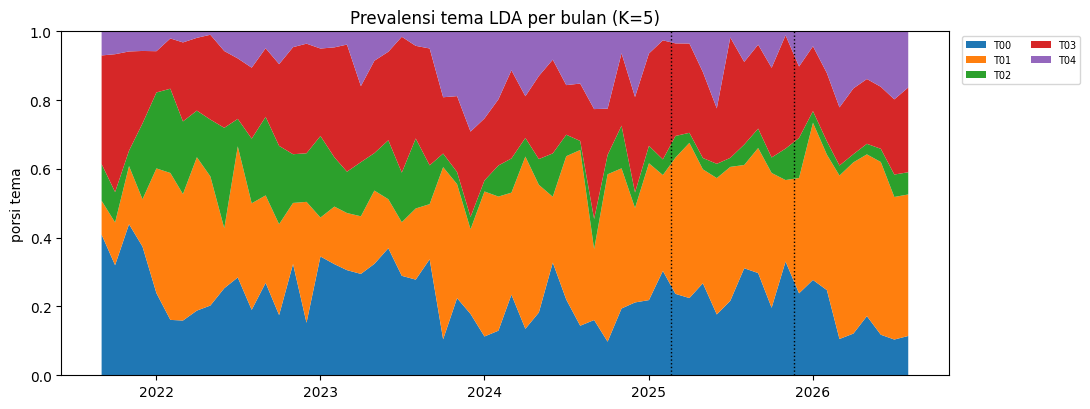

In [11]:
TOPIC_NAMES = {}      # opsional: isi nama tema, mis. {0: "perang & sanksi", 3: "bank sentral"}
art = pd.DataFrame(THETA[has_split], columns=[f"T{k:02d}" for k in range(K_LDA)])
art["bulan"] = articles.loc[has_split, "aligned_trading_date"].dt.to_period("M").to_numpy()
mon = art.groupby("bulan").mean()
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.stackplot(mon.index.to_timestamp(), mon.T.to_numpy(),
             labels=[TOPIC_NAMES.get(k, c) for k, c in enumerate(mon.columns)])
for key in ("train", "val"):
    ax.axvline(pd.Timestamp(splits[key]["end"]), color="k", ls=":", lw=1)
ax.set_ylim(0, 1); ax.set_ylabel("porsi tema"); ax.set_title(f"Prevalensi tema LDA per bulan (K={K_LDA})")
ax.legend(fontsize=7, ncol=2, loc="upper left", bbox_to_anchor=(1.01, 1)); plt.tight_layout(); plt.show()

## 6. Fitur harian dari tema

- **Porsi tema harian:** rata-rata porsi tema (LDA) atau proporsi artikel per tema (BERTopic) pada hari itu. Satu kolom dibuang karena porsi berjumlah 1 (kolinearitas). Hari tanpa berita diisi **porsi rata-rata hari train** (netral).
- **Sentimen per tema:** rata-rata sentimen FinBERT artikel (P(positive) − P(negative), dari cache) per tema, hanya untuk **5 tema terbesar di train**. Hari tanpa artikel tema itu diisi 0.
- **Pembanding global (H2):** satu fitur, rata-rata sentimen FinBERT semua artikel hari itu.

In [12]:
has_news = (daily["news_count"] > 0).to_numpy()

def daily_mean(M):
    """Rata-rata per aligned_trading_date; hari tanpa berita = rata-rata hari train (netral)."""
    df = pd.DataFrame(M[has_split]); df["date"] = articles.loc[has_split, "aligned_trading_date"].to_numpy()
    d = df.groupby("date").mean().reindex(daily["date"])
    has = d.notna().all(axis=1).to_numpy(); out = d.to_numpy(float).copy()
    out[~has] = out[tr & has].mean(axis=0)
    return out

def theme_sentiment(assign, tids, net):
    df = pd.DataFrame({"date": articles.loc[has_split, "aligned_trading_date"].to_numpy(),
                       "t": assign[has_split], "net": net[has_split]})
    piv = df.groupby(["date", "t"])["net"].mean().unstack().reindex(index=daily["date"], columns=tids)
    return piv.fillna(0.0).to_numpy()

# sentimen FinBERT per artikel (dari cache)
FB_OK = False
fb_f = CACHE_DIR / "FinBERT_cw300_mc2_ml512.npz"
if fb_f.exists():
    z = np.load(fb_f, allow_pickle=True); lab = {v: k for k, v in z["labels"].item().items()}
    NET = z["P"][:, lab["positive"]] - z["P"][:, lab["negative"]]; FB_OK = True
else:
    print("cache FinBERT belum ada -> fitur sentimen dilewati")

FEAT = {}      # nama set -> (matriks fitur teks, nama kolom)
SH_LDA = daily_mean(THETA)[:, :-1]
FEAT[f"T  porsi LDA (K={K_LDA})"] = (SH_LDA, [f"T{k:02d}" for k in range(K_LDA - 1)])
top_lda = list(np.argsort(-np.bincount(LDA_HARD[is_tr], minlength=K_LDA))[:5])
if FB_OK:
    G_NET = daily_mean(NET[:, None])
    FEAT["G  sentimen FinBERT global (1 fitur)"] = (G_NET, ["net_global"])
    S_LDA = theme_sentiment(LDA_HARD, top_lda, NET)
    FEAT["T  sentimen per tema LDA (top 5)"] = (S_LDA, [f"sent_T{k:02d}" for k in top_lda])
    FEAT["T  porsi + sentimen per tema LDA"] = (np.hstack([SH_LDA, S_LDA]),
        [f"T{k:02d}" for k in range(K_LDA - 1)] + [f"sent_T{k:02d}" for k in top_lda])
if BT_OK:
    ONEHOT = np.stack([(BT == t) for t in T_IDS], axis=1).astype(float)     # tanpa kolom outlier
    SH_BT = daily_mean(ONEHOT)
    FEAT[f"T  porsi BERTopic ({len(T_IDS)} tema)"] = (SH_BT, [f"B{t:02d}" for t in T_IDS])
    if FB_OK:
        top_bt = [T_IDS[i] for i in np.argsort(-np.array([(BT[is_tr] == t).sum() for t in T_IDS]))[:5]]
        S_BT = theme_sentiment(BT, top_bt, NET)
        FEAT["T  sentimen per tema BERTopic (top 5)"] = (S_BT, [f"sent_B{t:02d}" for t in top_bt])
print({k: v[0].shape for k, v in FEAT.items()})

{'T  porsi LDA (K=5)': (1194, 4), 'G  sentimen FinBERT global (1 fitur)': (1194, 1), 'T  sentimen per tema LDA (top 5)': (1194, 5), 'T  porsi + sentimen per tema LDA': (1194, 9), 'T  porsi BERTopic (13 tema)': (1194, 13), 'T  sentimen per tema BERTopic (top 5)': (1194, 5)}


### Korelasi tema dengan target (hanya hari train yang punya berita)
Spearman antara tiap fitur tema dan target (return besok). Karena banyak fitur diuji sekaligus, p dikoreksi **Bonferroni** (`p_bonf` = p × jumlah uji). Hanya `p_bonf < 0,05` yang pantas disebut hubungan nyata.

In [13]:
rows_c = []
m_tr = tr & has_news
for set_name, (F, names) in FEAT.items():
    if set_name.startswith("T  porsi +"): continue
    for j, n in enumerate(names):
        if F[m_tr, j].std() == 0: continue
        rho, p = spearmanr(F[m_tr, j], y[m_tr]); rows_c.append((set_name, n, rho, p))
corr = pd.DataFrame(rows_c, columns=["set", "fitur", "rho", "p"])
corr["p_bonf"] = (corr["p"] * len(corr)).clip(upper=1.0)
print(f"{len(corr)} uji | n hari = {int(m_tr.sum())}")
corr.sort_values("p").head(12).round(4)

28 uji | n hari = 734


,set,fitur,rho,p,p_bonf
19,T porsi BERTopic (13 tema),B09,0.0766,0.0379,1.0
2,T porsi LDA (K=5),T02,0.0734,0.0467,1.0
16,T porsi BERTopic (13 tema),B06,-0.0598,0.1054,1.0
4,G sentimen FinBERT global (1 fitur),net_global,-0.0561,0.1292,1.0
10,T porsi BERTopic (13 tema),B00,0.0543,0.1414,1.0
23,T sentimen per tema BERTopic (top 5),sent_B00,-0.0537,0.1465,1.0
11,T porsi BERTopic (13 tema),B01,-0.0483,0.1908,1.0
1,T porsi LDA (K=5),T01,0.0465,0.2081,1.0
7,T sentimen per tema LDA (top 5),sent_T00,-0.0455,0.2180,1.0
13,T porsi BERTopic (13 tema),B03,-0.0433,0.2416,1.0


## 7. Protokol evaluasi (identik dengan Bagian A, B, dan B.i)

In [14]:
MODELS = {
    "Ridge": lambda s: Ridge(alpha=10.0),
    "RandForest": lambda s: RandomForestRegressor(n_estimators=200, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=s),
    "GradBoost": lambda s: GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.03, subsample=0.8, random_state=s),
}
SEEDS = (0, 1, 2)

def direction_metrics(y_true, y_pred):
    m = y_true != 0
    t, p = y_true[m] > 0, y_pred[m] > 0
    return {"BalAcc": balanced_accuracy_score(t, p), "MCC": matthews_corrcoef(t, p)}

def fit_predict(X):
    Xs = StandardScaler().fit(X[tr]).transform(X)
    preds = {}
    for name, make in MODELS.items():
        seeds = (0,) if name == "Ridge" else SEEDS
        preds[name] = np.mean([make(s).fit(Xs[tr], y[tr]).predict(Xs) for s in seeds], axis=0)
    return preds

rows = []
def run(set_name, X):
    for mname, p in fit_predict(X).items():
        for sp, mask in (("val", va), ("test", te)):
            r = evaluate(y[mask], p[mask]); r.update(direction_metrics(y[mask], p[mask]))
            rows.append(dict(set=set_name, model=mname, split=sp, **r))

ret_today = daily["ret"].to_numpy(); base_rows = []
for sp, mask in (("val", va), ("test", te)):
    nb = naive_baselines(y[mask], ret_today[mask])
    nb["Konstan (mean train)"] = evaluate(y[mask], np.full(mask.sum(), y[tr].mean()))
    preds = {"Prediksi 0": np.zeros(mask.sum()), "Return kemarin": ret_today[mask],
             "Konstan (mean train)": np.full(mask.sum(), y[tr].mean())}
    for name, r in nb.items():
        r = dict(r); r.update(direction_metrics(y[mask], preds[name]))
        base_rows.append(dict(set=name, model="-", split=sp, **r))

In [15]:
KURS = daily[KURS_COLS].to_numpy(); LEX = daily[LEX_COLS].to_numpy()
run("A  kurs", KURS)
run("B  kurs+lexicon", np.hstack([KURS, LEX]))
for name, (F, _) in FEAT.items():
    run(name, np.hstack([KURS, F]))
res = pd.DataFrame(rows); base = pd.DataFrame(base_rows)
print("selesai:", res["set"].nunique(), "set x", res["model"].nunique(), "model")

selesai: 8 set x 3 model


## 8. Hasil

### 8.1 Pembanding tanpa model

In [16]:
cols = ["MAE", "RMSE", "DirAcc", "BalAcc", "MCC"]
base.pivot(index="set", columns="split", values=cols).round(5)

MAE              RMSE            DirAcc          BalAcc               MCC         
split                    test      val     test      val     test      val   test      val     test      val
set                                                                                                         
Konstan (mean train)  0.00218  0.00246  0.00289  0.00338  0.59091  0.53409  0.500  0.50000  0.00000  0.00000
Prediksi 0            0.00221  0.00247  0.00291  0.00338  0.00000  0.00000  0.500  0.50000  0.00000  0.00000
Return kemarin        0.00308  0.00347  0.00398  0.00461  0.54545  0.50568  0.539  0.50908  0.07754  0.01816

### 8.2 Rata-rata 3 model per set fitur
`dRMSE%` terhadap A (negatif = lebih baik).

In [17]:
mean_tbl = res.groupby(["set", "split"])[["RMSE", "DirAcc", "BalAcc", "MCC"]].mean().unstack("split")
a_rmse = mean_tbl.loc["A  kurs", "RMSE"]
for sp in ("val", "test"):
    mean_tbl[("dRMSE%", sp)] = (mean_tbl[("RMSE", sp)] / a_rmse[sp] - 1) * 100
mean_tbl = mean_tbl.sort_values(("RMSE", "val"))
mean_tbl.round(5)

RMSE            DirAcc            BalAcc               MCC            dRMSE%         
split                                     test      val     test      val     test      val     test      val      val     test
set                                                                                                                            
T  porsi BERTopic (13 tema)            0.00297  0.00339  0.43939  0.50189  0.50499  0.51604  0.01324  0.03385 -1.14486 -1.91688
T  sentimen per tema BERTopic (top 5)  0.00305  0.00341  0.42045  0.48106  0.49466  0.50640 -0.03046  0.01637 -0.71532  0.88348
A  kurs                                0.00303  0.00343  0.40720  0.47159  0.49769  0.49728 -0.03028 -0.01454  0.00000  0.00000
T  porsi LDA (K=5)                     0.00300  0.00344  0.42424  0.47348  0.49430  0.49412 -0.02143 -0.00859  0.18799 -0.86454
B  kurs+lexicon                        0.00301  0.00346  0.44318  0.45644  0.49181  0.47557 -0.02755 -0.04702  0.62909 -0.47218
G  sentimen FinBERT global (1 fitur)   0.00306  0.00346  0.40909  0.46591  0.49858  0.49118 -0.01593 -0.03051  0.81739  1.00725
T  porsi + sentimen per tema LDA       0.00303  0.00350  0.44697  0.43939  0.50570  0.45701  0.00768 -0.09793  1.97255  0.19772
T  sentimen per tema LDA (top 5)       0.00313  0.00352  0.43371  0.42992  0.51015  0.45308  0.03397 -0.13927  2.63758  3.33335

### 8.3 Per model (RMSE val)

In [18]:
pm = res[res["split"] == "val"].pivot(index="set", columns="model", values="RMSE")
pm["rata2"] = pm.mean(axis=1); pm.sort_values("rata2").round(6)

model,GradBoost,RandForest,Ridge,rata2
set,,,,
T porsi BERTopic (13 tema),0.003379,0.003427,0.003378,0.003395
T sentimen per tema BERTopic (top 5),0.003380,0.003461,0.003387,0.003409
A kurs,0.003421,0.003493,0.003388,0.003434
T porsi LDA (K=5),0.003444,0.003483,0.003393,0.003440
B kurs+lexicon,0.003449,0.003493,0.003424,0.003456
G sentimen FinBERT global (1 fitur),0.003478,0.003517,0.003392,0.003462
T porsi + sentimen per tema LDA,0.003517,0.003559,0.003429,0.003502
T sentimen per tema LDA (top 5),0.003528,0.003622,0.003424,0.003524


### 8.4 Grafik

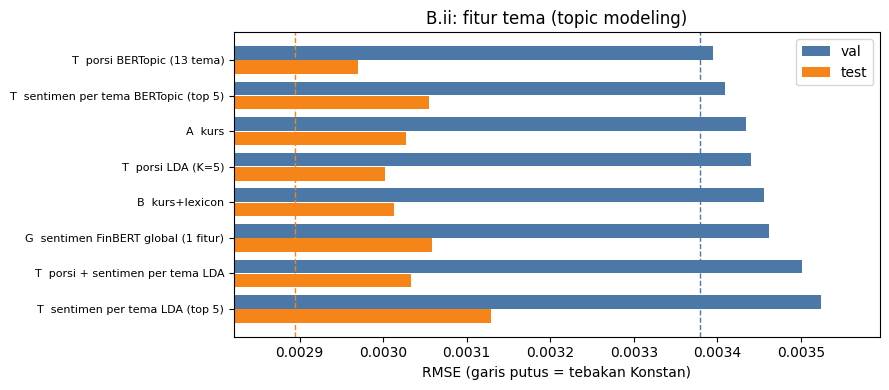

In [19]:
plot_df = mean_tbl["RMSE"].sort_values("val", ascending=False)
const = base[base["set"] == "Konstan (mean train)"].set_index("split")["RMSE"]
fig, ax = plt.subplots(figsize=(9, max(4, 0.34 * len(plot_df))))
yy = np.arange(len(plot_df))
ax.barh(yy + 0.2, plot_df["val"], height=0.38, label="val", color="#4C78A8")
ax.barh(yy - 0.2, plot_df["test"], height=0.38, label="test", color="#F58518")
ax.axvline(const["val"], color="#4C78A8", ls="--", lw=1); ax.axvline(const["test"], color="#F58518", ls="--", lw=1)
ax.set_yticks(yy); ax.set_yticklabels(plot_df.index, fontsize=8)
ax.set_xlim(plot_df.min().min() * 0.95, plot_df.max().max() * 1.02)
ax.set_xlabel("RMSE (garis putus = tebakan Konstan)"); ax.legend()
ax.set_title("B.ii: fitur tema (topic modeling)"); plt.tight_layout(); plt.show()

## 9. Catatan metodologi
- **Tidak ada kebocoran:** kamus/filter LDA, model LDA, dan BERTopic (UMAP + HDBSCAN) hanya di-fit pada artikel train; K dipilih dari koherensi train. Val/test hanya di-transform.
- **Tema berbasis kata sensitif** pada stopword dan kata generik. Tema yang terlihat tidak bermakna biasanya perlu kamus stopword yang lebih baik, bukan model yang lebih rumit.
- **Banyak uji:** puluhan korelasi/set fitur diuji, jadi sebagian "temuan" muncul karena kebetulan. Pakai `p_bonf` dan kekonsistenan val/test.
- **Pembanding utama tetap baris Konstan.** Selisih < 1-2% anggap noise kecuali konsisten.

## 10. Kesimpulan (isi sendiri setelah membaca tabel)
1. **H3:** apakah tema LDA/BERTopic bisa dinamai dan masuk akal? Apakah prevalensinya naik di periode peristiwa yang sesuai? Berapa porsi outlier BERTopic?
ya. Kedua metode menghasilkan tema geopolitik yang bisa ditafsirkan dan prevalensinya mengikuti peristiwa nyata. Ini hasil deskriptif yang kuat untuk laporan.

2. **H1:** apakah A + porsi tema (LDA/BERTopic) konsisten lebih baik dari A di val **dan** test? Berapa dRMSE%?
sedikit, hanya BERTopic. Penurunan sekitar 1–2%, muncul pada ketiga model, tapi kecil dan dipilih dari beberapa set yang diuji. LDA K=5 yang lebih kasar tidak menunjukkan gain.

3. **H2:** apakah sentimen per tema lebih baik dari sentimen global (set G)? Apakah ada tema dengan `p_bonf` < 0,05?
Fiturnya jarang terisi, jadi menambah noise dan hasilnya sama atau lebih buruk dari A.

4. Apakah ada set yang mengalahkan baris Konstan? tidak. Tidak ada hubungan tema–target yang signifikan setelah koreksi Bonferroni.

5. Apakah topic modeling layak dipakai di Model C akhir, atau cukup sebagai analisis deskriptif di laporan?